# 07 - Daily Risk Series

Builds the daily risk table: one row per ticker and trading day. The other risk files are one number per stock (`risk_metrics`) or one per month (`risk_monthly`); this one shows how risk **changes day by day**, so Power BI can draw volatility and drawdown over time and the ML model can use them as features.

| Column | Meaning |
|---|---|
| `ticker`, `date` | Primary key |
| `vol_20d_ann` | Std of the last 20 daily returns x sqrt(252): recent volatility, about one month |
| `vol_63d_ann` | The same over 63 trading days: about one quarter, smoother |
| `running_peak` | Highest close up to and including that day |
| `drawdown` | `close / running_peak - 1`. 0 at a new high, -0.30 = 30% below the peak. It recovers when the price recovers |

**Why two windows:** a short window reacts quickly to a shock; a long one shows the underlying level. When the 20-day line is far above the 63-day line, risk has just jumped.

**Warm-up:** volatility needs a full window. The first day has no return, so `vol_20d_ann` is empty for the first 20 days of each stock (the first value is on day 21, when 20 returns exist), and `vol_63d_ann` for the first 63 days. These are left empty, not filled.

**Output:** `data/processed/risk_daily.csv`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "risk").exists())
sys.path.insert(0, str(ROOT))

RAW_FILE = ROOT / "data" / "raw" / "yahoo_prices_raw.csv"
OUT_FILE = ROOT / "data" / "processed" / "risk_daily.csv"
TRADING_DAYS = 252
WINDOWS = {"vol_20d_ann": 20, "vol_63d_ann": 63}
print("Project root:", ROOT)

Project root: d:\DEPI\MarketPulse Graduation Project


## 1. Load prices

In [2]:
df = pd.read_csv(RAW_FILE, parse_dates=["date"])[["ticker", "date", "close"]]
df = df.sort_values(["ticker", "date"]).reset_index(drop=True)
print("Shape:", df.shape, "| Period:", df["date"].min().date(), "->", df["date"].max().date())
print("Tickers:", sorted(df["ticker"].unique()))

Shape: (12540, 3) | Period: 2021-01-04 -> 2025-12-30
Tickers: ['AAPL', 'AMZN', 'JNJ', 'JPM', 'KO', 'LLY', 'MSFT', 'NVDA', 'TSLA', 'XOM']


## 2. Calculate

All figures are calculated per ticker on its full history, so no window mixes two stocks.

In [3]:
by_ticker = df.groupby("ticker")["close"]
df["return"] = by_ticker.pct_change()

for col, window in WINDOWS.items():
    df[col] = df.groupby("ticker")["return"].transform(
        lambda s, w=window: s.rolling(w, min_periods=w).std() * np.sqrt(TRADING_DAYS))

df["running_peak"] = by_ticker.cummax()
df["drawdown"] = df["close"] / df["running_peak"] - 1

risk_daily = df[["ticker", "date", "vol_20d_ann", "vol_63d_ann", "running_peak", "drawdown"]]
print("Rows:", len(risk_daily), "| Tickers:", risk_daily["ticker"].nunique())
risk_daily.groupby("ticker").tail(2).head(6)

Rows: 12540 | Tickers: 10


,ticker,date,vol_20d_ann,vol_63d_ann,running_peak,drawdown
1252,AAPL,2025-12-29,0.123793,0.174793,285.413116,-0.043433
1253,AAPL,2025-12-30,0.108157,0.174949,285.413116,-0.045809
2506,AMZN,2025-12-29,0.174455,0.330196,254.000000,-0.086339
2507,AMZN,2025-12-30,0.174286,0.329206,254.000000,-0.084528
3760,JNJ,2025-12-29,0.192378,0.156136,210.779724,-0.030863
3761,JNJ,2025-12-30,0.190593,0.151807,210.779724,-0.033898


## 3. Missing values

Only the warm-up days should be empty.

In [4]:
print(risk_daily.isna().sum().to_string())
first = risk_daily.groupby("ticker").size().iloc[0]
print(f"\nExpected empty: vol_20d_ann = 20 per stock ({20*10}), vol_63d_ann = 63 per stock ({63*10})")

ticker            0
date              0
vol_20d_ann     200
vol_63d_ann     630
running_peak      0
drawdown          0

Expected empty: vol_20d_ann = 20 per stock (200), vol_63d_ann = 63 per stock (630)


## 4. Checks

In [5]:
wide = df.pivot(index="date", columns="ticker", values="close")
ret_w = wide.pct_change()
ref20 = (ret_w.rolling(20).std() * np.sqrt(TRADING_DAYS)).stack().rename("ref")
ref63 = (ret_w.rolling(63).std() * np.sqrt(TRADING_DAYS)).stack().rename("ref")
ref_dd = (wide / wide.cummax() - 1).stack().rename("ref")
idx = risk_daily.set_index(["date", "ticker"])
RISK_METRICS = ROOT / "data" / "processed" / "risk_metrics.csv"

checks = {
    "Columns match the proposed table": list(risk_daily.columns) == ["ticker", "date", "vol_20d_ann", "vol_63d_ann", "running_peak", "drawdown"],
    "PK (ticker, date) is unique": not risk_daily.duplicated(["ticker", "date"]).any(),
    "Same number of days for every ticker": risk_daily.groupby("ticker").size().nunique() == 1,
    "Warm-up: 20 empty vol_20d_ann and 63 empty vol_63d_ann per ticker": bool(
        (risk_daily.groupby("ticker")["vol_20d_ann"].apply(lambda s: s.isna().sum()) == 20).all()
        and (risk_daily.groupby("ticker")["vol_63d_ann"].apply(lambda s: s.isna().sum()) == 63).all()),
    "No missing running_peak or drawdown": not risk_daily[["running_peak", "drawdown"]].isna().any().any(),
    "Volatility is never negative": bool((risk_daily[["vol_20d_ann", "vol_63d_ann"]].dropna() >= 0).all().all()),
    "Drawdown is between -100% and 0": bool(risk_daily["drawdown"].between(-1, 0).all()),
    "Drawdown is 0 on every day the close is a new high": bool((risk_daily.loc[df["close"] == df["running_peak"], "drawdown"] == 0).all()),
    "running_peak never goes down": bool(risk_daily.groupby("ticker")["running_peak"].apply(lambda s: s.is_monotonic_increasing).all()),
    "vol_20d_ann equals an independent calculation": bool(np.allclose(idx["vol_20d_ann"].dropna(), ref20.reindex(idx["vol_20d_ann"].dropna().index))),
    "vol_63d_ann equals an independent calculation": bool(np.allclose(idx["vol_63d_ann"].dropna(), ref63.reindex(idx["vol_63d_ann"].dropna().index))),
    "drawdown equals an independent calculation": bool(np.allclose(idx["drawdown"], ref_dd.reindex(idx.index))),
}
if RISK_METRICS.exists():
    rmx = pd.read_csv(RISK_METRICS, index_col="ticker")
    checks["Worst drawdown equals max_drawdown in risk_metrics.csv"] = bool(
        np.allclose(risk_daily.groupby("ticker")["drawdown"].min().reindex(rmx.index), rmx["max_drawdown"], atol=1e-4))
pd.Series(checks, name="passed").to_frame()

,passed
Columns match the proposed table,True
"PK (ticker, date) is unique",True
Same number of days for every ticker,True
Warm-up: 20 empty vol_20d_ann and 63 empty vol_63d_ann per ticker,True
No missing running_peak or drawdown,True
Volatility is never negative,True
Drawdown is between -100% and 0,True
Drawdown is 0 on every day the close is a new high,True
running_peak never goes down,True
vol_20d_ann equals an independent calculation,True


## 5. Charts

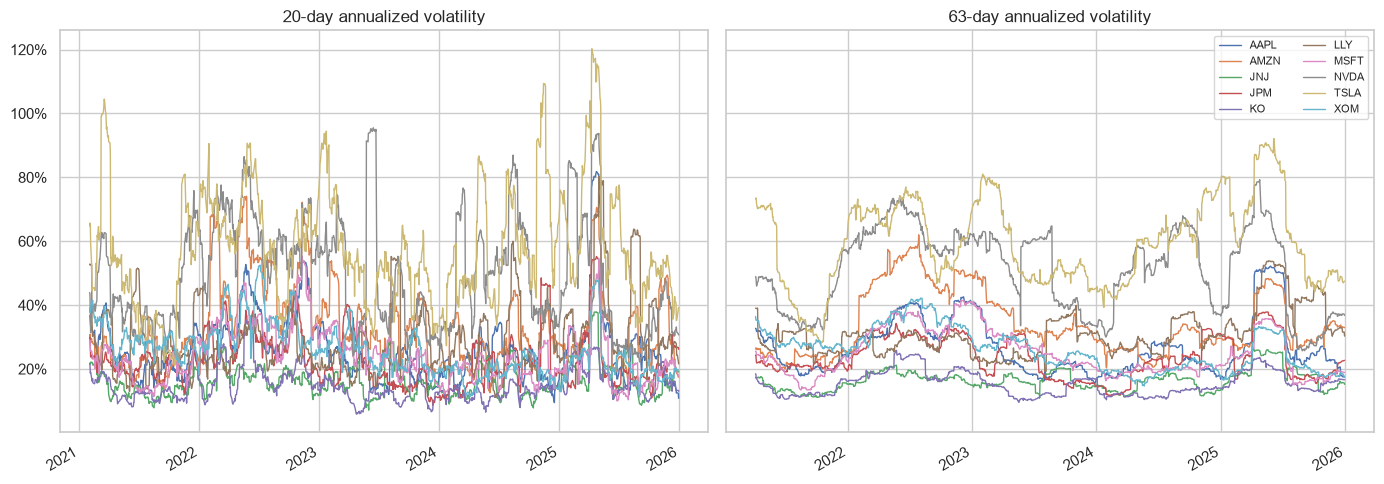

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col, title in zip(axes, ["vol_20d_ann", "vol_63d_ann"], ["20-day", "63-day"]):
    risk_daily.pivot(index="date", columns="ticker", values=col).plot(ax=ax, linewidth=1, legend=False)
    ax.set_title(f"{title} annualized volatility"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].legend(ncol=2, fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

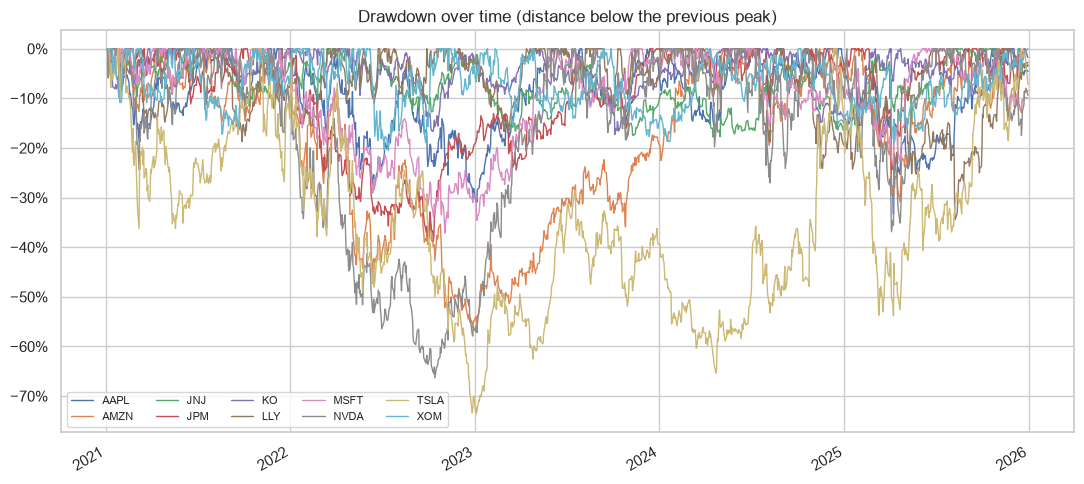

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
risk_daily.pivot(index="date", columns="ticker", values="drawdown").plot(ax=ax, linewidth=1)
ax.set_title("Drawdown over time (distance below the previous peak)")
ax.set_xlabel(""); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

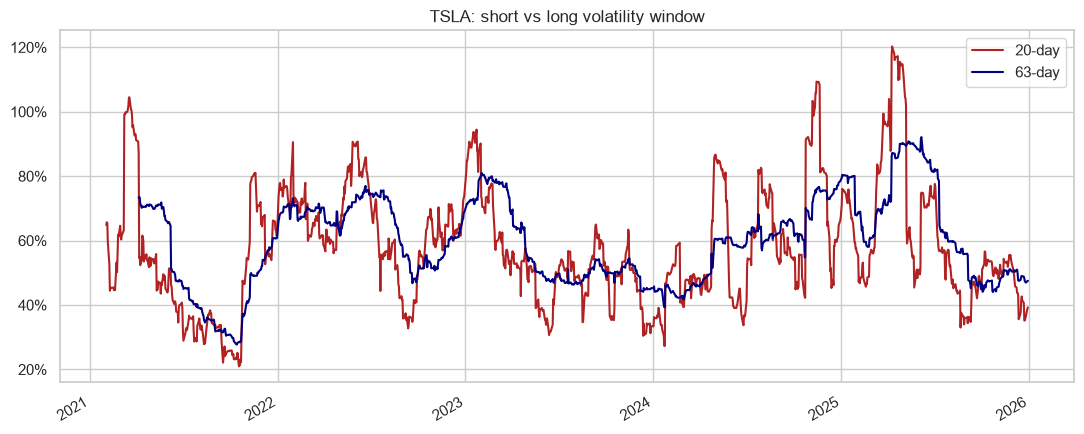

In [8]:
t = risk_daily["ticker"].iloc[0] if "TSLA" not in set(risk_daily["ticker"]) else "TSLA"
one = risk_daily[risk_daily["ticker"] == t].set_index("date")
fig, ax = plt.subplots(figsize=(11, 4.5))
one["vol_20d_ann"].plot(ax=ax, label="20-day", color="firebrick")
one["vol_63d_ann"].plot(ax=ax, label="63-day", color="navy")
ax.set_title(f"{t}: short vs long volatility window")
ax.set_xlabel(""); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
plt.tight_layout(); plt.show()

## 6. Key observations

In [9]:
last = risk_daily.sort_values("date").groupby("ticker").tail(1).set_index("ticker")
peak20 = risk_daily.loc[risk_daily["vol_20d_ann"].idxmax()]
worst = risk_daily.loc[risk_daily["drawdown"].idxmin()]
print(f"Latest day: {risk_daily['date'].max().date()}")
print(f"- Highest current 20-day volatility: {last['vol_20d_ann'].idxmax()} ({last['vol_20d_ann'].max():.1%})")
print(f"- Furthest below its peak now: {last['drawdown'].idxmin()} ({last['drawdown'].min():.1%}); {int((last['drawdown'] == 0).sum())} stock(s) at an all-time high")
print(f"- Highest 20-day volatility ever: {peak20['ticker']} on {peak20['date'].date()} ({peak20['vol_20d_ann']:.1%})")
print(f"- Deepest drawdown ever: {worst['ticker']} on {worst['date'].date()} ({worst['drawdown']:.1%})")

Latest day: 2025-12-30
- Highest current 20-day volatility: TSLA (39.2%)
- Furthest below its peak now: MSFT (-9.9%); 1 stock(s) at an all-time high
- Highest 20-day volatility ever: TSLA on 2025-04-10 (120.3%)
- Deepest drawdown ever: TSLA on 2023-01-03 (-73.6%)


## 7. Save

In [ ]:
OUT_FILE.parent.mkdir(parents=True, exist_ok=True)
risk_daily.to_csv(OUT_FILE, index=False)
print("Saved:", OUT_FILE, "|", len(risk_daily), "rows")

Saved: d:\DEPI\MarketPulse Graduation Project\data\processed\risk_daily.csv | 12540 rows


: 